In [19]:
%pip install kagglehub matplotlib pillow pyyaml

Note: you may need to restart the kernel to use updated packages.


In [20]:
import kagglehub
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image
from pathlib import Path
from collections import Counter, defaultdict


In [21]:
IMAGE_EXTENSIONS = {".jpeg", ".jpg", ".bmp", ".png"}
CLASS_NAMES = {
        0: "Glioma",
        1: "Meningioma",
        2: "No Tumor",
        3: "Pituitary"
        }

In [22]:
path = kagglehub.dataset_download(
    "ahmedsorour1/mri-for-brain-tumor-with-bounding-boxes"
)

DATA_DIR = Path(path)

print("Dataset path:", DATA_DIR)
print("Dataset exists:", DATA_DIR.exists())

Dataset path: /root/.cache/kagglehub/datasets/ahmedsorour1/mri-for-brain-tumor-with-bounding-boxes/versions/1
Dataset exists: True


In [23]:
print("\n========== DATASET STRUCTURE ==========")

for item in sorted(DATA_DIR.rglob("*")):
    relative_path = item.relative_to(DATA_DIR)
    depth = len(relative_path.parts)

    if depth <= 3:
        if item.is_dir():
            print(f"[DIR]  {relative_path}/")
        else:
            print(f"[FILE] {relative_path}")




========== DATASET STRUCTURE ==========
[DIR]  Train/
[DIR]  Train/Glioma/
[DIR]  Train/Glioma/images/
[DIR]  Train/Glioma/labels/
[DIR]  Train/Meningioma/
[DIR]  Train/Meningioma/images/
[DIR]  Train/Meningioma/labels/
[DIR]  Train/No Tumor/
[DIR]  Train/No Tumor/images/
[DIR]  Train/No Tumor/labels/
[DIR]  Train/Pituitary/
[DIR]  Train/Pituitary/images/
[DIR]  Train/Pituitary/labels/
[DIR]  Val/
[DIR]  Val/Glioma/
[DIR]  Val/Glioma/images/
[DIR]  Val/Glioma/labels/
[DIR]  Val/Meningioma/
[DIR]  Val/Meningioma/images/
[DIR]  Val/Meningioma/labels/
[DIR]  Val/No Tumor/
[DIR]  Val/No Tumor/images/
[DIR]  Val/No Tumor/labels/
[DIR]  Val/Pituitary/
[DIR]  Val/Pituitary/images/
[DIR]  Val/Pituitary/labels/


In [24]:
image_paths = sorted(
    p for p in DATA_DIR.rglob("*")
    if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS
)

label_paths = sorted(
    p for p in DATA_DIR.rglob("*")
    if p.is_file() and p.suffix.lower() == ".txt"
)

In [25]:
print("\n========== DATASET COUNTS ==========")
print("Number of images:", len(image_paths))
print("Number of TXT files:", len(label_paths))


========== DATASET COUNTS ==========
Number of images: 5249
Number of TXT files: 5249


In [26]:
print("========== Examples ==========")
print("\nExample images:")
for p in image_paths[:5]:
    print(p.relative_to(DATA_DIR))

print("\nExample annotation files:")
for p in label_paths[:5]:
    print(p.relative_to(DATA_DIR))



========== Examples ==========

Example images:
Train/Glioma/images/Te-glTr_0000.jpg
Train/Glioma/images/Te-glTr_0005.jpg
Train/Glioma/images/Te-glTr_0007.jpg
Train/Glioma/images/Te-gl_0014.jpg
Train/Glioma/images/Te-gl_0015.jpg

Example annotation files:
Train/Glioma/labels/Te-glTr_0000.txt
Train/Glioma/labels/Te-glTr_0005.txt
Train/Glioma/labels/Te-glTr_0007.txt
Train/Glioma/labels/Te-gl_0014.txt
Train/Glioma/labels/Te-gl_0015.txt


In [27]:
print("\nClass mapping:")
for class_id, class_name in sorted(CLASS_NAMES.items()):
    print(f"{class_id}: {class_name}")



Class mapping:
0: Glioma
1: Meningioma
2: No Tumor
3: Pituitary


In [28]:
labels_by_stem = defaultdict(list)

for label_path in label_paths:
    labels_by_stem[label_path.stem].append(label_path)

image_label_pairs = []
missing_labels = []
ambiguous_images = []

for image_path in image_paths:
    candidates = labels_by_stem.get(image_path.stem, [])

    if len(candidates) == 1:
        image_label_pairs.append((image_path, candidates[0]))

    elif len(candidates) == 0:
        missing_labels.append(image_path)

    else:
        image_parts = image_path.relative_to(DATA_DIR).parts[:-1]

        def common_parent_length(label_path):
            label_parts = label_path.relative_to(DATA_DIR).parts[:-1]
            common = 0

            for a, b in zip(image_parts, label_parts):
                if a != b:
                    break
                common += 1

            return common

        ranked = sorted(
            candidates,
            key=common_parent_length,
            reverse=True
        )

        best_score = common_parent_length(ranked[0])

        if (
            best_score > 0
            and (
                len(ranked) == 1
                or common_parent_length(ranked[1]) < best_score
            )
        ):
            image_label_pairs.append((image_path, ranked[0]))
        else:
            ambiguous_images.append(image_path)

In [29]:
print("\n========== IMAGE-LABEL MATCHING ==========")
print("Matched pairs:", len(image_label_pairs))
print("Images without labels:", len(missing_labels))
print("Images with ambiguous labels:", len(ambiguous_images))



========== IMAGE-LABEL MATCHING ==========
Matched pairs: 5247
Images without labels: 2
Images with ambiguous labels: 0


In [30]:
if missing_labels:
    print("\nExamples of images without labels:")
    for p in missing_labels[:10]:
        print(p.relative_to(DATA_DIR))

if ambiguous_images:
    print("\nExamples with ambiguous labels:")
    for p in ambiguous_images[:10]:
        print(p.relative_to(DATA_DIR))


Examples of images without labels:
Val/No Tumor/images/image(55).jpg
Val/No Tumor/images/image(61).jpg


In [31]:
def read_yolo_labels(label_path):

    annotations = []
    invalid_lines = []

    with open(label_path, "r", encoding="utf-8") as file:
        for line_number, line in enumerate(file, start=1):
            line = line.strip()

            # Empty lines are ignored
            if not line:
                continue

            values = line.split()

            if len(values) != 5:
                invalid_lines.append(
                    (line_number, "Expected exactly 5 values")
                )
                continue

            try:
                class_value = float(values[0])
                coordinates = list(map(float, values[1:]))

                if not class_value.is_integer():
                    invalid_lines.append(
                        (line_number, "Class ID must be an integer")
                    )
                    continue

                class_id = int(class_value)
                x_center, y_center, width, height = coordinates

            except ValueError:
                invalid_lines.append(
                    (line_number, "Non-numeric value")
                )
                continue

            if class_id not in CLASS_NAMES:
                invalid_lines.append(
                    (line_number, f"Unknown class ID: {class_id}")
                )
                continue

            if not all(
                0 <= value <= 1
                for value in (x_center, y_center, width, height)
            ):
                invalid_lines.append(
                    (line_number, "Coordinates must be between 0 and 1")
                )
                continue

            if width <= 0 or height <= 0:
                invalid_lines.append(
                    (line_number, "Width and height must be positive")
                )
                continue

            annotations.append(
                (class_id, x_center, y_center, width, height)
            )

    return annotations, invalid_lines


In [32]:
# Display a real annotation file
print("\n========== EXAMPLE YOLO ANNOTATION ==========")

example_found = False

for image_path, label_path in image_label_pairs:
    try:
        annotations, invalid_lines = read_yolo_labels(label_path)

        if annotations:
            print("Image:", image_path.relative_to(DATA_DIR))
            print("Label:", label_path.relative_to(DATA_DIR))
            print("Raw annotation content:")
            print(label_path.read_text(encoding="utf-8"))

            print("\nInterpreted annotations:")
            for annotation in annotations:
                class_id, xc, yc, w, h = annotation
                print(
                    f"Class: {CLASS_NAMES[class_id]}, "
                    f"x_center={xc}, y_center={yc}, "
                    f"width={w}, height={h}"
                )

            example_found = True
            break

    except OSError as error:
        print(f"Could not read {label_path}: {error}")

if not example_found:
    print("No valid non-empty annotation found.")


========== EXAMPLE YOLO ANNOTATION ==========
Image: Train/Glioma/images/Te-glTr_0000.jpg
Label: Train/Glioma/labels/Te-glTr_0000.txt
Raw annotation content:
0 0.555664 0.653320 0.146484 0.193359


Interpreted annotations:
Class: Glioma, x_center=0.555664, y_center=0.65332, width=0.146484, height=0.193359


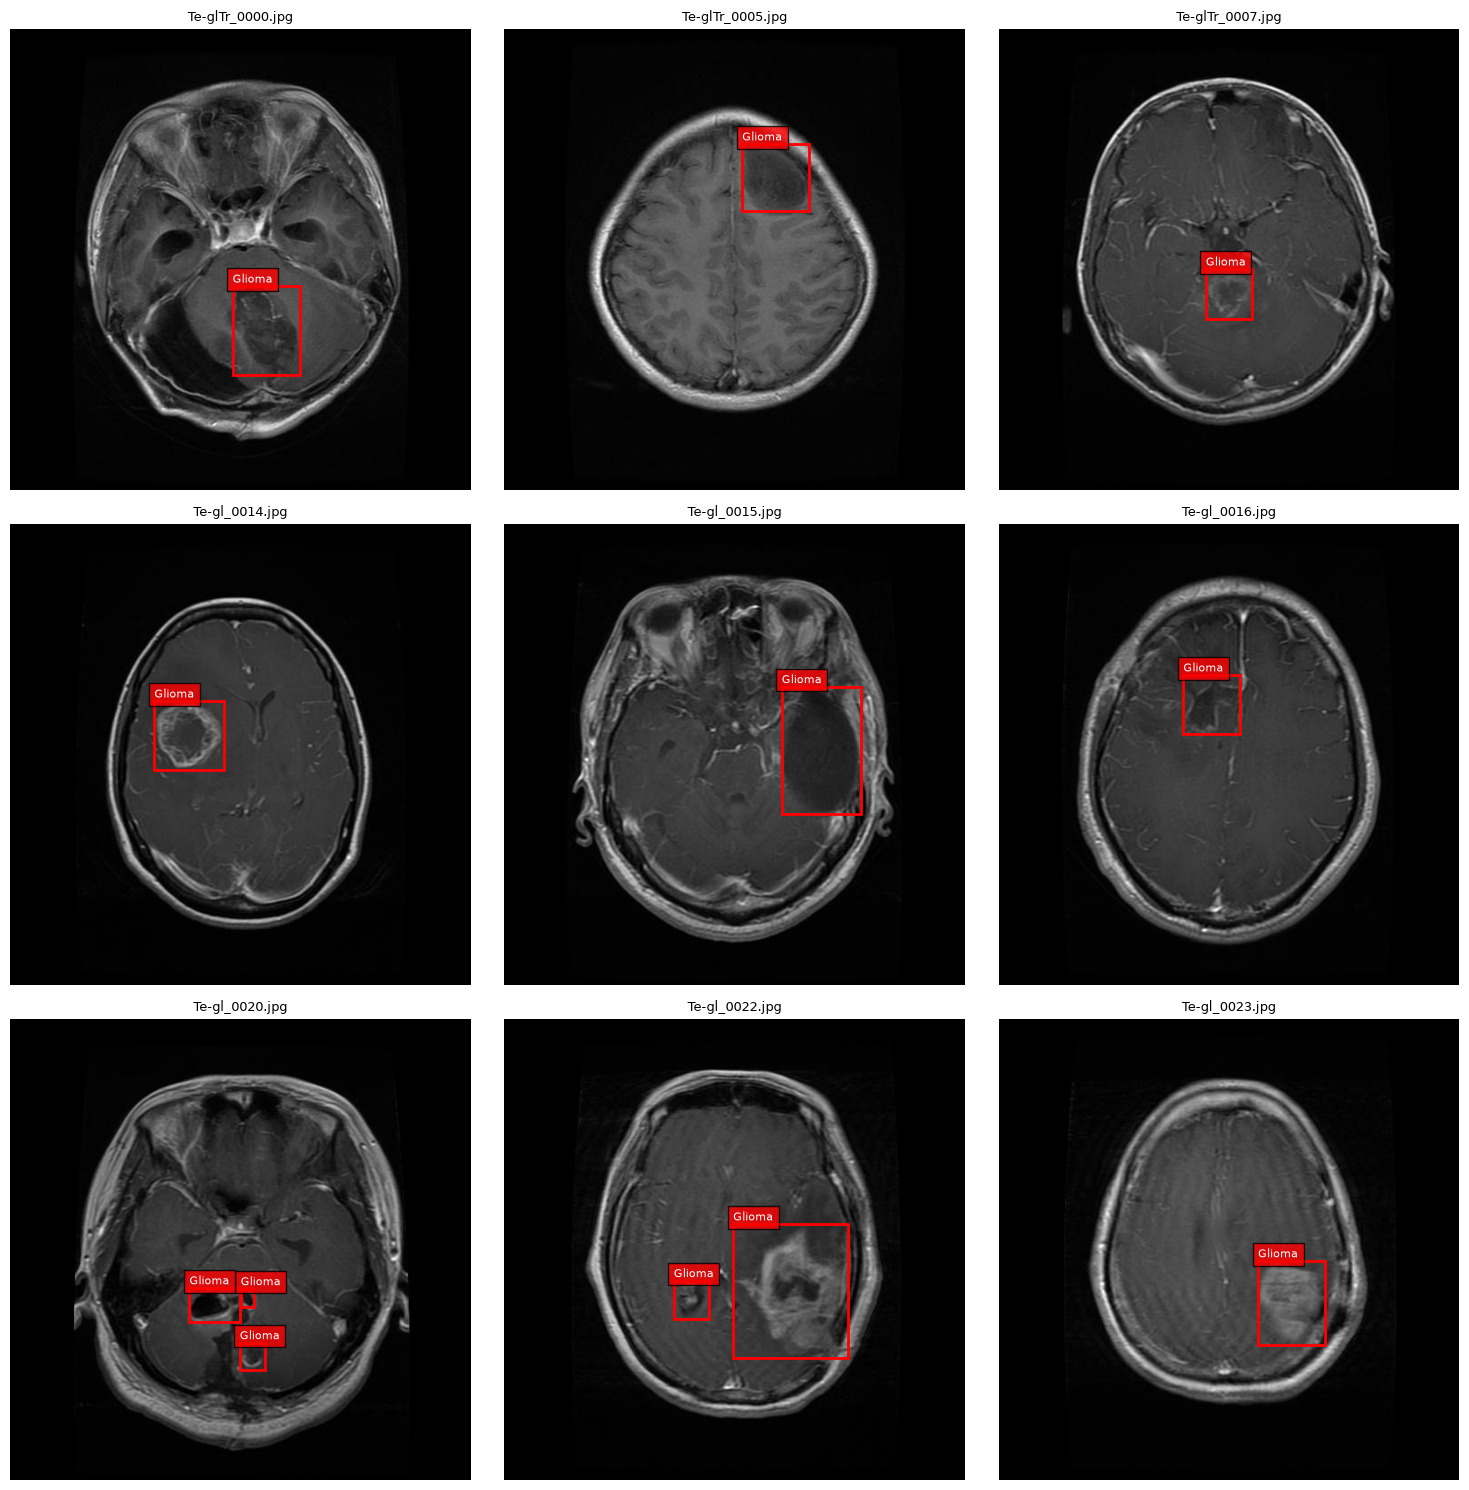

In [33]:
def show_mri_samples(pairs, n=9):
    samples = pairs[:n]

    if not samples:
        print("No matched image-label pairs to display.")
        return

    fig, axes = plt.subplots(3, 3, figsize=(15, 15))
    axes = axes.flatten()

    for ax in axes:
        ax.axis("off")

    for ax, (image_path, label_path) in zip(axes, samples):

        with Image.open(image_path) as source:
            image = source.convert("RGB")

        image_width, image_height = image.size
        annotations, invalid_lines = read_yolo_labels(label_path)

        ax.imshow(image)
        ax.set_title(image_path.name, fontsize=9)

        for class_id, xc, yc, w, h in annotations:
            # Convert normalized YOLO coordinates to pixels
            x_min = (xc - w / 2) * image_width
            y_min = (yc - h / 2) * image_height
            box_width = w * image_width
            box_height = h * image_height

            rect = patches.Rectangle(
                (x_min, y_min),
                box_width,
                box_height,
                linewidth=2,
                edgecolor="red",
                facecolor="none"
            )

            ax.add_patch(rect)

            class_name = CLASS_NAMES[class_id]

            ax.text(
                x_min,
                max(0, y_min - 4),
                class_name,
                color="white",
                fontsize=8,
                bbox={
                    "facecolor": "red",
                    "alpha": 0.8
                }
            )

        if invalid_lines:
            print(
                f"{label_path.name}: "
                f"{len(invalid_lines)} invalid annotation line(s)"
            )

    plt.tight_layout()
    plt.show()


show_mri_samples(image_label_pairs, n=9)

In [34]:
images_per_class = Counter()
boxes_per_class = Counter()

empty_label_count = 0
invalid_line_count = 0
unreadable_label_count = 0
unreadable_image_count = 0

for image_path, label_path in image_label_pairs:
    try:
        # Check that the image can actually be opened
        with Image.open(image_path) as image:
            image.verify()

        annotations, invalid_lines = read_yolo_labels(label_path)
        invalid_line_count += len(invalid_lines)

        # An empty file, or a file with no valid annotations,
        # is counted here for preliminary inspection.
        if not annotations:
            empty_label_count += 1
            continue

        # Count every valid bounding box
        for class_id, xc, yc, w, h in annotations:
            boxes_per_class[class_id] += 1

        # Count a class only once per image
        classes_in_image = {
            class_id
            for class_id, xc, yc, w, h in annotations
        }

        for class_id in classes_in_image:
            images_per_class[class_id] += 1

    except OSError as error:
        unreadable_image_count += 1
        print(f"Unreadable image {image_path}: {error}")

    except (ValueError, UnicodeError) as error:
        unreadable_label_count += 1
        print(f"Unreadable label {label_path}: {error}")

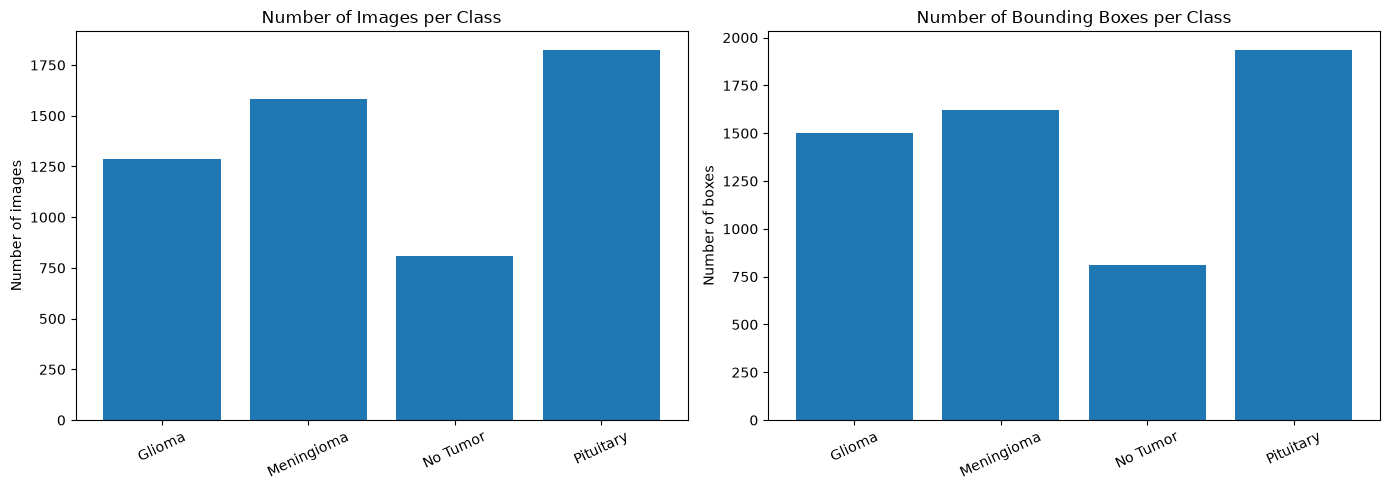

In [35]:
class_ids = sorted(CLASS_NAMES.keys())
class_labels = [CLASS_NAMES[class_id] for class_id in class_ids]

image_counts = [
    images_per_class[class_id]
    for class_id in class_ids
]

box_counts = [
    boxes_per_class[class_id]
    for class_id in class_ids
]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].bar(class_labels, image_counts)
axes[0].set_title("Number of Images per Class")
axes[0].set_ylabel("Number of images")
axes[0].tick_params(axis="x", rotation=25)

axes[1].bar(class_labels, box_counts)
axes[1].set_title("Number of Bounding Boxes per Class")
axes[1].set_ylabel("Number of boxes")
axes[1].tick_params(axis="x", rotation=25)

plt.tight_layout()
plt.show()


In [36]:
print("\n========== FINAL DATASET SUMMARY ==========")

print("Total images discovered:", len(image_paths))
print("Total TXT files discovered:", len(label_paths))
print("Matched image-label pairs:", len(image_label_pairs))
print("Images without matching labels:", len(missing_labels))
print("Images with ambiguous labels:", len(ambiguous_images))
print("Empty or annotation-free label files:", empty_label_count)
print("Invalid annotation lines:", invalid_line_count)
print("Unreadable images:", unreadable_image_count)
print("Unreadable annotation files:", unreadable_label_count)

print("\nClass distribution:")
print("-" * 55)

for class_id in class_ids:
    print(
        f"{CLASS_NAMES[class_id]:12} | "
        f"Images: {images_per_class[class_id]:5} | "
        f"Boxes: {boxes_per_class[class_id]:5}"
    )

print("-" * 55)



========== FINAL DATASET SUMMARY ==========
Total images discovered: 5249
Total TXT files discovered: 5249
Matched image-label pairs: 5247
Images without matching labels: 2
Images with ambiguous labels: 0
Empty or annotation-free label files: 1
Invalid annotation lines: 0
Unreadable images: 0
Unreadable annotation files: 0

Class distribution:
-------------------------------------------------------
Glioma       | Images:  1287 | Boxes:  1502
Meningioma   | Images:  1582 | Boxes:  1624
No Tumor     | Images:   809 | Boxes:   809
Pituitary    | Images:  1825 | Boxes:  1936
-------------------------------------------------------
